# 準備：Colabから量子回路を動かす

**できるようになること**：教材を開く／小さな回路を実行する／量子実機へ接続する／対象分子を確認する。

全員が基本操作を行い、実機への試行は各チームの代表者が担当します。
所属企業の利用枠を今回の用途で利用できる方はそちらを使い、それ以外の希望者は講師が案内するFlex枠を使います。

1. GitHubの「Open in Colab」をクリック。
2. Colabの「ファイル → ドライブにコピーを保存」で自分のコピーを作成。
3. 標準のCPUランタイムで、上から実行。GPUは不要です。
4. Google Driveのマウントも不要です。結果ファイルを残す際はダウンロードします。

In [1]:
# GitHub → Colab / ローカルの共通セットアップ
import sys, subprocess, importlib.util
from pathlib import Path
GITHUB_REPOSITORY = "https://github.com/QS-laboratory/IBM_handson.git"
GITHUB_REF = "main"
try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IS_COLAB = False
if IS_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "qiskit==2.4.1", "qiskit-ibm-runtime==0.43.1", "pylatexenc==2.10"], check=True)
    checkout = Path("/content/IBM_handson")
    if not checkout.exists():
        subprocess.run(["git", "clone", GITHUB_REPOSITORY, str(checkout)], check=True)
    subprocess.run(["git", "-C", str(checkout), "fetch", "origin", GITHUB_REF, "--depth", "1"], check=True)
    subprocess.run(["git", "-C", str(checkout), "checkout", "--detach", "FETCH_HEAD"], check=True)
    WORKSHOP_ROOT = checkout / "hands_on"
else:
    candidates = [Path.cwd(), Path.cwd()/"hands_on", Path.cwd().parent]
    WORKSHOP_ROOT = next(p for p in candidates if (p/"src/workshop.py").exists())
sys.path.insert(0, str(WORKSHOP_ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import *
import qiskit
print("Qiskit:", qiskit.__version__)
print("教材:", WORKSHOP_ROOT)
print("実機への送信は、明示的に有効化したセルだけが行います。")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def show_circuit(qc):
    try:
        figure = qc.draw("mpl", fold=90)
        display(figure)
        plt.close(figure)
    except ImportError:
        print(qc.draw("text", fold=90))

Qiskit: 2.4.1
教材: /Users/sato/project/FTQC_HandsOn/hands_on
実機への送信は、明示的に有効化したセルだけが行います。


## 小さな回路：0/1の確率を変える
`theta`を0、π/2、πへ変えてみてください。状態ベクトルの各成分の絶対値の2乗が確率です。

P(0), P(1) = [0.5 0.5]


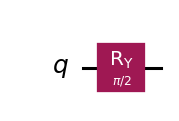

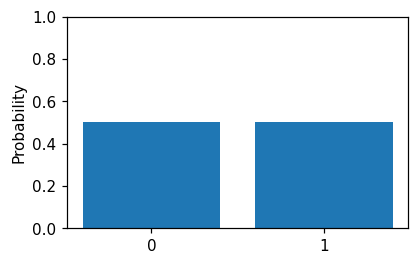

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
theta = np.pi/2
small = QuantumCircuit(1)
small.ry(theta, 0)
show_circuit(small)
probabilities = Statevector.from_instruction(small).probabilities()
print("P(0), P(1) =", probabilities)
fig, ax = plt.subplots(figsize=(4, 2.5))
ax.bar(["0", "1"], probabilities); ax.set_ylim(0,1)
ax.set_ylabel("Probability"); plt.show()

## 2量子ビットに相関を作る
Hで重ね合わせを作り、CNOTで相関を作ります。理想計算と、1024回測定したときのばらつきを比較します。
Qiskitのビット列は右端がq0です。これは本編・分子データでも共通です。
第一版の発展教材だけは数式の上からの並びに変換する関数を使うため、変換規則を明記しています。

Ideal probabilities: {np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}
Simulated counts: {np.str_('00'): np.int64(496), np.str_('11'): np.int64(528)}


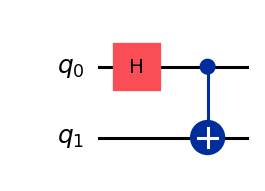

In [3]:
bell = QuantumCircuit(2)
bell.h(0); bell.cx(0, 1)
show_circuit(bell)
state = Statevector.from_instruction(bell)
state.seed(19)
print("Ideal probabilities:", state.probabilities_dict())
print("Simulated counts:", state.sample_counts(1024))

## IBM実機への接続

- IBM Quantum Platformで対象インスタンスへの利用権限を確認し、APIキーを用意します。
- Colab左側の鍵アイコン「シークレット」に `IBM_QUANTUM_API_KEY` を登録し、このノートへのアクセスを許可します。
- 利用するインスタンスのCRNを下のセルへ入力します。APIキーはセルへ直接書きません。
- `CONNECT_IBM = True` にして接続します。このセルは接続と一覧取得のみです。

手順： https://quantum.cloud.ibm.com/docs/en/guides/initialize-account

利用可能な実機が表示されない場合は、アカウント・インスタンスの権限・地域を講師と確認してください。

In [4]:
# 接続を試すときだけTrueに変更。APIキーをコードや出力へ書かないでください。
CONNECT_IBM = False
INSTANCE_CRN = ""  # 今回利用できる所属企業の枠、または講師が案内するFlex枠
BACKEND_NAME = ""  # 接続後、利用可能な実機から講師と相談して指定
service = None
if CONNECT_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    if not INSTANCE_CRN:
        raise ValueError("利用権限のあるインスタンスのCRNを指定してください")
    if IS_COLAB:
        from google.colab import userdata
        api_key = userdata.get("IBM_QUANTUM_API_KEY")
    else:
        from getpass import getpass
        api_key = getpass("IBM Quantum API key: ")
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=api_key, instance=INSTANCE_CRN)
    del api_key
    print("利用可能な実機:", [b.name for b in service.backends(operational=True, simulator=False)])
else:
    print("IBM接続はスキップ。ローカル演習と配布データの解析は続けられます。")

IBM接続はスキップ。ローカル演習と配布データの解析は続けられます。


### チーム代表者：Bell回路を実機へ送信

以下は実機利用枠を消費します。講師の合図で `RUN_BELL = True` にします。
ジョブIDは送信直後に保存します。Colabから切断されても、再投入せずジョブIDから結果を取得できます。
待ち時間に次の「対象分子」へ進んでください。

In [5]:
RUN_BELL = False
bell_record_path = OUTPUT_DIR / "bell_submission.json"
if RUN_BELL:
    if service is None or not BACKEND_NAME:
        raise ValueError("IBM接続とBACKEND_NAMEの指定が必要です")
    if bell_record_path.exists():
        raise FileExistsError("既存ジョブを先に確認してください")
    from qiskit_ibm_runtime import SamplerV2
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    backend = service.backend(BACKEND_NAME)
    measured_bell = bell.copy(); measured_bell.measure_all()
    isa = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=11).run(measured_bell)
    job = SamplerV2(mode=backend).run([isa], shots=1024)
    write_json(bell_record_path, {"job_id":job.job_id(), "backend":BACKEND_NAME})
    print("Job ID:", job.job_id())
else:
    print("Bell回路の実機送信はスキップ")

Bell回路の実機送信はスキップ


In [6]:
FETCH_BELL = False
if FETCH_BELL:
    if service is None: raise ValueError("IBMへ接続してください")
    bell_record = read_json(bell_record_path)
    saved_job = service.job(bell_record["job_id"])
    print("Status:", saved_job.status())
    if "DONE" in str(saved_job.status()).upper():
        print(saved_job.result()[0].data.meas.get_counts())

## 今日の分子を確認する
ブタジエンを共通の主題材にし、実機演習の初期設定は5量子ビットのエチレンとします。
9量子ビットのブタジエンは同じAPIで切り替えられますが、現在の回路は深く、講師による事前検証を条件にします。

計算条件は固定された教材用構造・STO-3G・π活性空間のCASCIです。
これは実験値を予測する精密な分子計算ではありません。

ethylene CAS (2, 2) total qubits 5 S0-T1 gap/eV 4.7837
butadiene CAS (4, 4) total qubits 9 S0-T1 gap/eV 3.7024


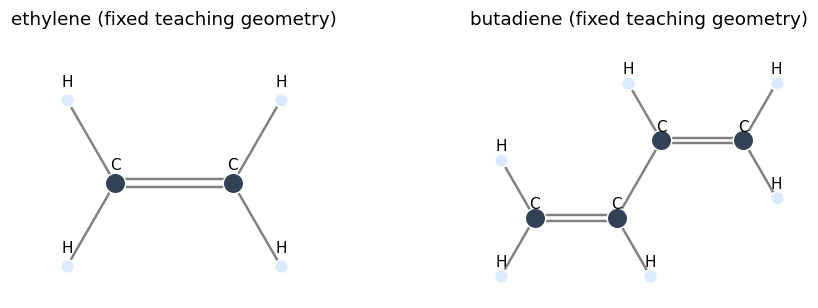

In [7]:
for molecule in ["ethylene", "butadiene"]:
    meta, _ = load_model(molecule)
    print(molecule, "CAS", (meta["active_electrons"], meta["active_spatial_orbitals"]),
          "total qubits", meta["total_qpde_qubits"], "S0-T1 gap/eV", round(meta["gap_ev"], 4))
fig, axes = plt.subplots(1,2,figsize=(10,3))
for name, ax in zip(["ethylene","butadiene"],axes): plot_molecule(name, ax)
plt.show()

**準備完了の確認**：回路を表示できた／理想確率と測定回数を区別できた／チームの実機利用担当が決まった／対象分子と計算する2状態を説明できた。

次は `01_circuits_and_ibm.ipynb` を開きます。認証は各Colabランタイムで必要です。APIキーはノート間でコピーせず同じシークレットから読み込みます。